# Phase 2 — Detailed Training-Only Exploratory Data Analysis

All target-based EDA uses only `data/governed/train.csv`. Validation and test rows remain outside analytical decisions.

## 1. Imports, configuration, and source

In [1]:
from pathlib import Path
import json, warnings, joblib
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display, Markdown
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns",50); pd.set_option("display.float_format",lambda x:f"{x:,.4f}")
sns.set_theme(style="whitegrid",context="notebook")
BLUE,ORANGE,INK="#4C78A8","#F58518","#263238"
root=Path.cwd()
if not (root/"data/raw/ai4i2020.csv").exists(): root=root.parent
raw=pd.read_csv(root/"data/governed/train.csv")
TARGET="Machine failure"; IDS=["UDI","Product ID"]; LEAK=["TWF","HDF","PWF","OSF","RNF"]
BASE=["Type","Air temperature [K]","Process temperature [K]","Rotational speed [rpm]","Torque [Nm]","Tool wear [min]"]
print('Governed training shape:',raw.shape)

Governed training shape: (7000, 14)


## 2. Dataset overview

In [2]:
display(raw.head(10)); raw.info()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,932,L48111,L,295.5000,305.9000,1542,36.2000,12,0,0,0,0,0,0
1,7448,M22307,M,300.3000,311.9000,1677,30.8000,48,0,0,0,0,0,0
2,1291,L48470,L,298.6000,309.7000,1429,45.8000,113,0,0,0,0,0,0
3,1293,M16152,M,298.7000,309.7000,1868,23.8000,118,0,0,0,0,0,0
4,7044,M21903,M,300.7000,310.6000,2006,19.1000,102,0,0,0,0,0,0
5,9934,L57113,L,298.3000,308.3000,1597,32.4000,69,0,0,0,0,0,0
6,8915,M23774,M,297.3000,308.5000,1524,49.3000,176,0,0,0,0,0,0
7,4577,M19436,M,302.9000,311.1000,1926,21.8000,58,0,0,0,0,0,0
8,9668,L56847,L,299.2000,310.3000,1352,48.9000,238,1,0,0,0,1,0
9,7331,H36744,H,299.8000,310.2000,1537,36.6000,191,0,0,0,0,0,0


<class 'pandas.DataFrame'>
RangeIndex: 7000 entries, 0 to 6999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      7000 non-null   int64  
 1   Product ID               7000 non-null   str    
 2   Type                     7000 non-null   str    
 3   Air temperature [K]      7000 non-null   float64
 4   Process temperature [K]  7000 non-null   float64
 5   Rotational speed [rpm]   7000 non-null   int64  
 6   Torque [Nm]              7000 non-null   float64
 7   Tool wear [min]          7000 non-null   int64  
 8   Machine failure          7000 non-null   int64  
 9   TWF                      7000 non-null   int64  
 10  HDF                      7000 non-null   int64  
 11  PWF                      7000 non-null   int64  
 12  OSF                      7000 non-null   int64  
 13  RNF                      7000 non-null   int64  
dtypes: float64(3), int64(9), str(2)
mem

## 3. Data types and cardinality

In [3]:
display(pd.DataFrame({'dtype':raw.dtypes.astype(str),'unique':raw.nunique(),'non_null':raw.notna().sum()}))

,dtype,unique,non_null
UDI,int64,7000,7000
Product ID,str,7000,7000
Type,str,3,7000
Air temperature [K],float64,92,7000
Process temperature [K],float64,82,7000
Rotational speed [rpm],int64,861,7000
Torque [Nm],float64,550,7000
Tool wear [min],int64,243,7000
Machine failure,int64,2,7000
TWF,int64,2,7000


## 4. Descriptive statistics

In [4]:
display(raw.describe(include='all').T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
UDI,"7,000.0000",NaN,NaN,NaN,"5,004.6019","2,869.3923",1.0000,"2,512.7500","5,011.5000","7,487.2500","10,000.0000"
Product ID,7000,7000,L48111,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Type,7000,3,L,4248,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Air temperature [K],"7,000.0000",NaN,NaN,NaN,300.0365,2.0013,295.3000,298.4000,300.1000,301.5250,304.4000
Process temperature [K],"7,000.0000",NaN,NaN,NaN,310.0255,1.4832,305.7000,308.8000,310.1000,311.1000,313.8000
Rotational speed [rpm],"7,000.0000",NaN,NaN,NaN,"1,538.3483",177.4437,"1,181.0000","1,424.0000","1,502.0000","1,612.0000","2,874.0000"
Torque [Nm],"7,000.0000",NaN,NaN,NaN,40.0216,9.9662,4.2000,33.2000,40.1000,46.8000,75.4000
Tool wear [min],"7,000.0000",NaN,NaN,NaN,108.5786,63.7326,0.0000,54.0000,108.0000,164.0000,253.0000
Machine failure,"7,000.0000",NaN,NaN,NaN,0.0339,0.1809,0.0000,0.0000,0.0000,0.0000,1.0000
TWF,"7,000.0000",NaN,NaN,NaN,0.0046,0.0675,0.0000,0.0000,0.0000,0.0000,1.0000


## 5. Missingness, duplicates, and identifier integrity

In [5]:
q=pd.DataFrame({'missing':raw.isna().sum(),'missing_pct':100*raw.isna().mean()})
display(q); print("Full duplicates",raw.duplicated().sum()); print("UDI duplicates",raw.UDI.duplicated().sum()); print("Product ID duplicates",raw["Product ID"].duplicated().sum())

,missing,missing_pct
UDI,0,0.0000
Product ID,0,0.0000
Type,0,0.0000
Air temperature [K],0,0.0000
Process temperature [K],0,0.0000
Rotational speed [rpm],0,0.0000
Torque [Nm],0,0.0000
Tool wear [min],0,0.0000
Machine failure,0,0.0000
TWF,0,0.0000


Full duplicates 0
UDI duplicates 0
Product ID duplicates 0


## 6. Valid-range and consistency checks

In [6]:
checks=pd.Series({
'nonpositive rotational speed':(raw['Rotational speed [rpm]']<=0).sum(),
'negative torque':(raw['Torque [Nm]']<0).sum(),
'negative tool wear':(raw['Tool wear [min]']<0).sum(),
'process <= air temperature':(raw['Process temperature [K]']<=raw['Air temperature [K]']).sum(),
'nonbinary target':(~raw[TARGET].isin([0,1])).sum()})
display(checks.to_frame('rows'))

,rows
nonpositive rotational speed,0
negative torque,0
negative tool wear,0
process <= air temperature,0
nonbinary target,0


## 7. Target distribution

,count,pct
Machine failure,,
No failure,6763,96.6143
Failure,237,3.3857


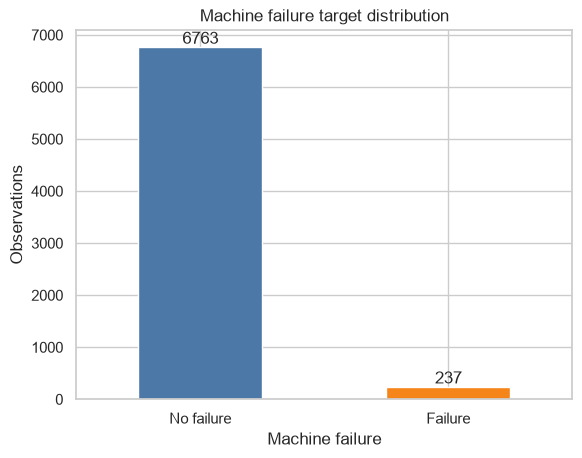

In [7]:
d=raw[TARGET].value_counts().sort_index().rename(index={0:'No failure',1:'Failure'})
display(pd.DataFrame({'count':d,'pct':100*d/len(raw)})); ax=d.plot.bar(color=[BLUE,ORANGE],rot=0,title='Machine failure target distribution'); ax.bar_label(ax.containers[0]); ax.set_ylabel('Observations'); plt.show()

## 8. Product-type composition

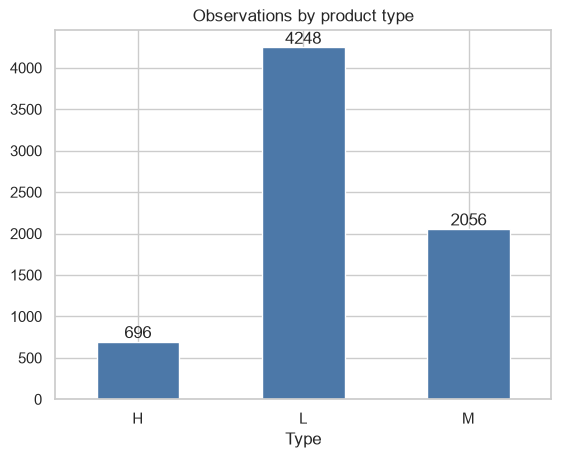

,count
Type,
H,696
L,4248
M,2056


In [8]:
s=raw.Type.value_counts().sort_index(); ax=s.plot.bar(color=BLUE,rot=0,title='Observations by product type'); ax.bar_label(ax.containers[0]); plt.show(); display(s.to_frame('count'))

## 9. Failure rate by product type

,size,sum,mean,rate_pct
Type,,,,
H,696,14,0.0201,2.0115
L,4248,158,0.0372,3.7194
M,2056,65,0.0316,3.1615


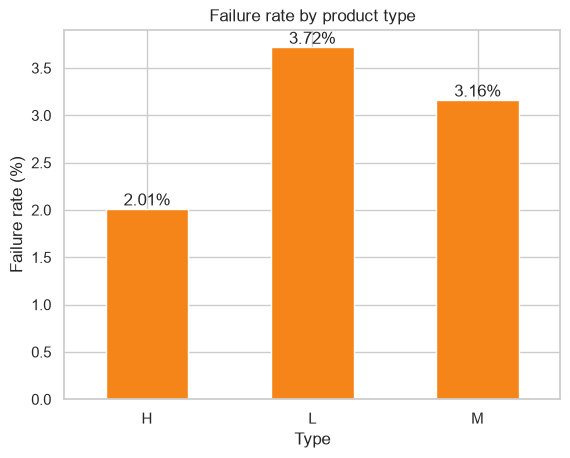

In [9]:
s=raw.groupby('Type')[TARGET].agg(['size','sum','mean']); s['rate_pct']=100*s['mean']; display(s)
ax=s.rate_pct.plot.bar(color=ORANGE,rot=0,title='Failure rate by product type'); ax.set_ylabel('Failure rate (%)'); ax.bar_label(ax.containers[0],fmt='%.2f%%'); plt.show()

## 10. Numeric univariate distributions

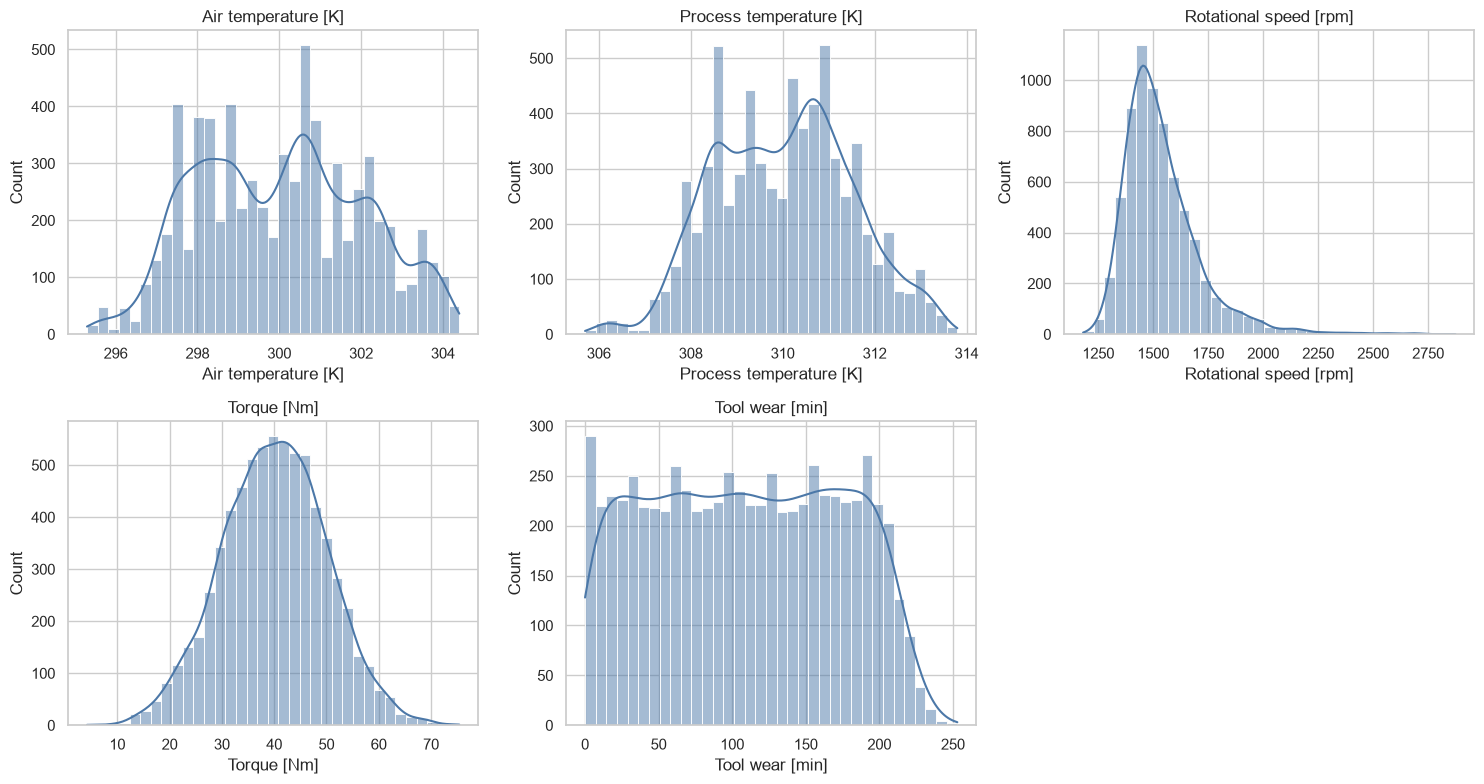

In [10]:
cols=BASE[1:]; fig,axs=plt.subplots(2,3,figsize=(15,8)); 
for c,ax in zip(cols,axs.flat): sns.histplot(raw[c],bins=35,kde=True,color=BLUE,ax=ax); ax.set_title(c)
axs.flat[-1].axis('off'); plt.tight_layout(); plt.show()

## 11. Numeric outlier profiles

In [11]:
rows=[]
for c in BASE[1:]:
 q1,q3=raw[c].quantile([.25,.75]); i=q3-q1; m=~raw[c].between(q1-1.5*i,q3+1.5*i); rows.append((c,q1,q3,i,m.sum(),100*m.mean()))
display(pd.DataFrame(rows,columns=['feature','q1','q3','iqr','outside','outside_pct']).sort_values('outside_pct',ascending=False))

,feature,q1,q3,iqr,outside,outside_pct
2,Rotational speed [rpm],"1,424.0000","1,612.0000",188.0000,302,4.3143
3,Torque [Nm],33.2000,46.8000,13.6000,42,0.6000
0,Air temperature [K],298.4000,301.5250,3.1250,0,0.0000
1,Process temperature [K],308.8000,311.1000,2.3000,0,0.0000
4,Tool wear [min],54.0000,164.0000,110.0000,0,0.0000


## 12. Feature distributions by target

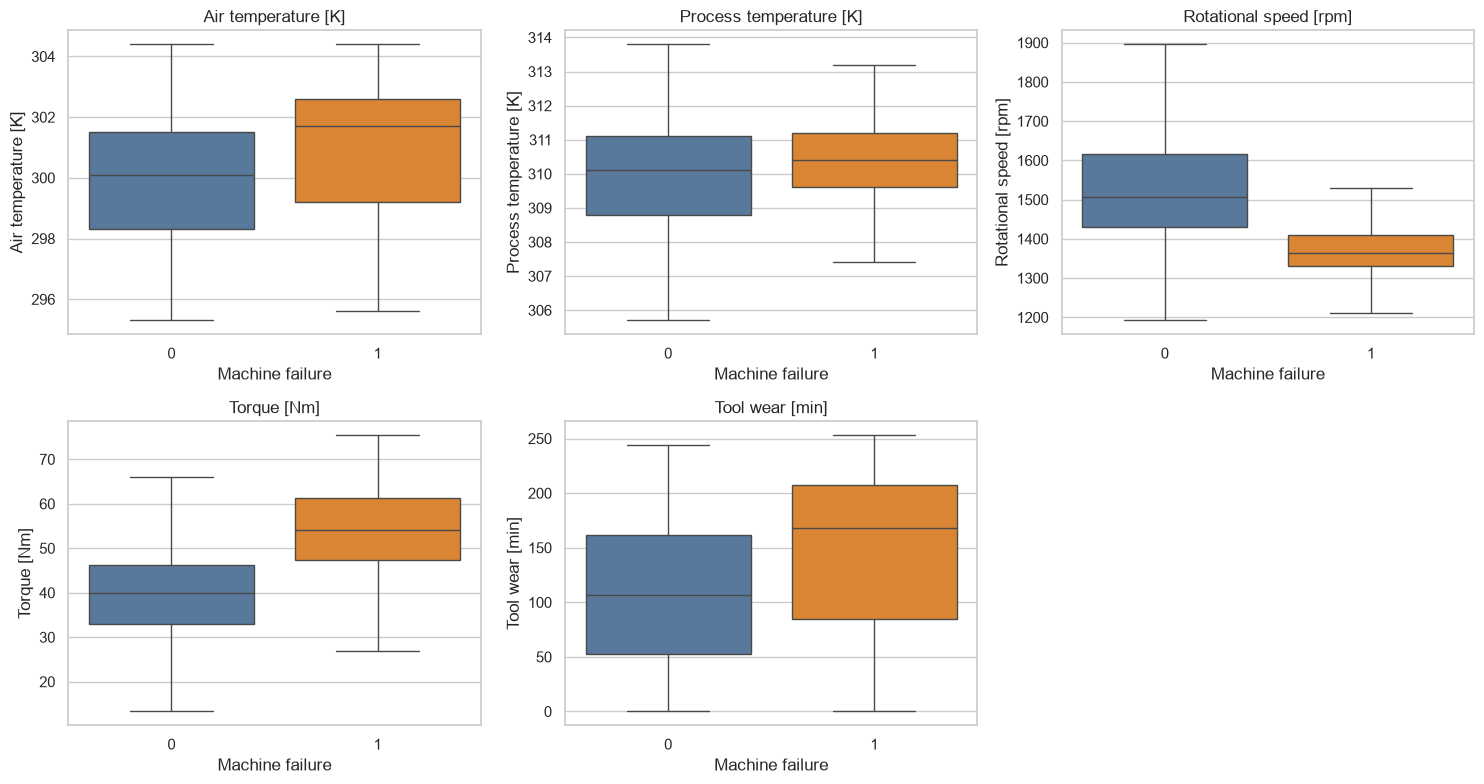

In [12]:
fig,axs=plt.subplots(2,3,figsize=(15,8))
for c,ax in zip(BASE[1:],axs.flat): sns.boxplot(data=raw,x=TARGET,y=c,hue=TARGET,palette={0:BLUE,1:ORANGE},legend=False,showfliers=False,ax=ax); ax.set_title(c)
axs.flat[-1].axis('off'); plt.tight_layout(); plt.show()

## 13. Failure rates across numeric quantiles

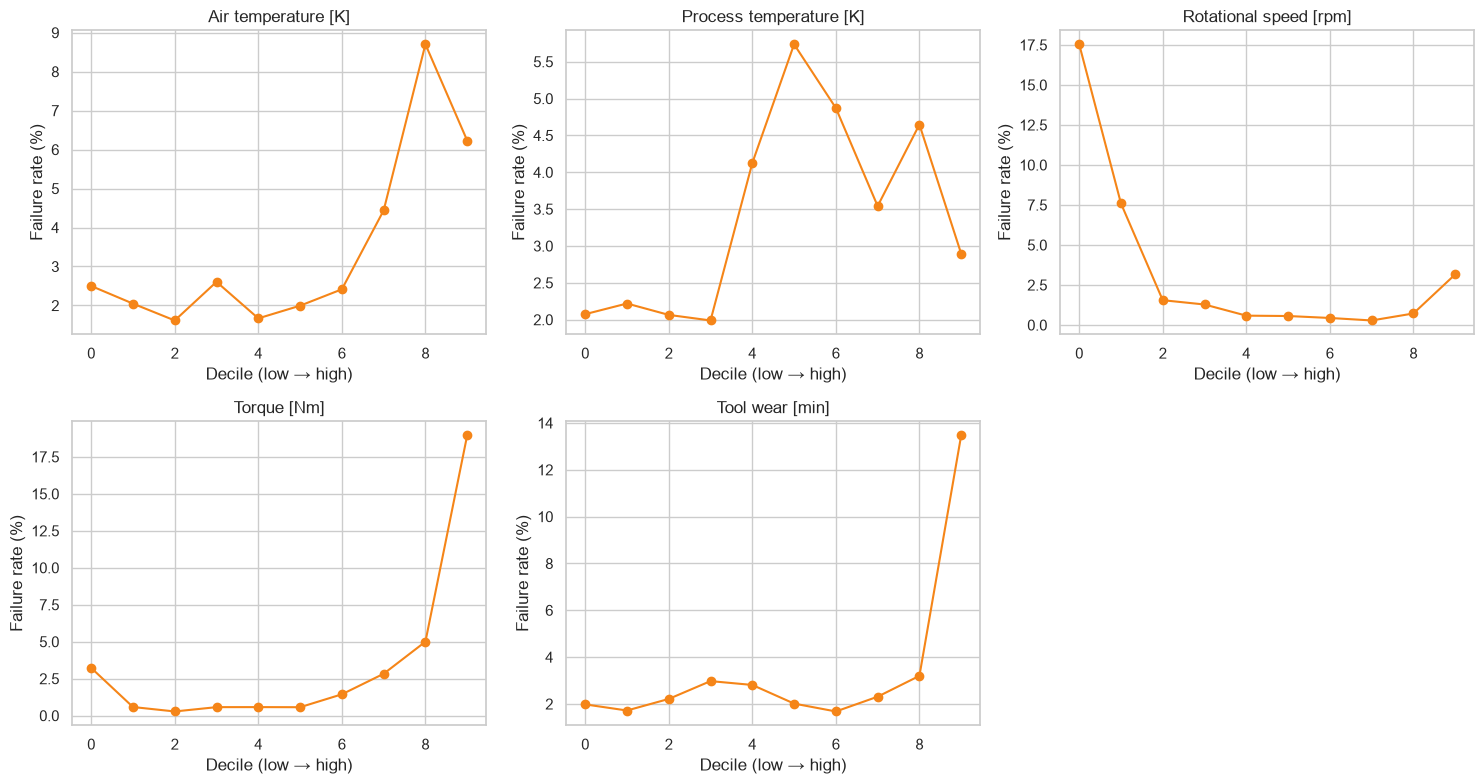

In [13]:
fig,axs=plt.subplots(2,3,figsize=(15,8))
for c,ax in zip(BASE[1:],axs.flat):
 b=pd.qcut(raw[c],10,duplicates='drop'); z=raw.groupby(b,observed=True)[TARGET].mean()*100; ax.plot(range(len(z)),z,marker='o',color=ORANGE); ax.set(title=c,xlabel='Decile (low → high)',ylabel='Failure rate (%)')
axs.flat[-1].axis('off'); plt.tight_layout(); plt.show()

## 14. Temperature relationship

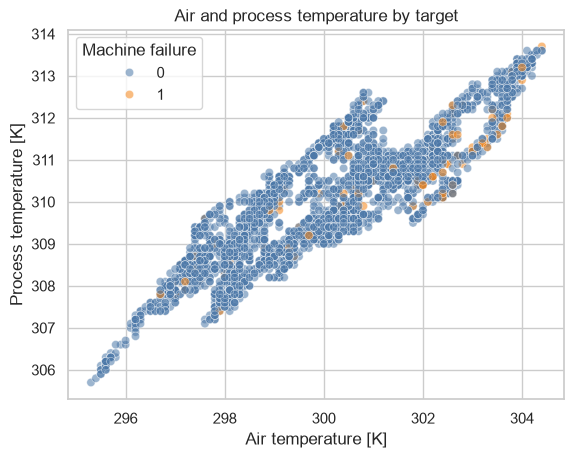

,count,mean,std,min,25%,50%,75%,max
Machine failure,,,,,,,,
0,"6,763.0000",10.0109,0.9937,7.6000,9.3000,9.8000,11.0000,12.1000
1,237.0000,9.3654,1.1771,7.6000,8.4000,9.2000,10.5000,12.0000


In [14]:
x=raw.sample(3000,random_state=42); sns.scatterplot(data=x,x='Air temperature [K]',y='Process temperature [K]',hue=TARGET,palette={0:BLUE,1:ORANGE},alpha=.55); plt.title('Air and process temperature by target'); plt.show()
raw.assign(temp_delta=raw['Process temperature [K]']-raw['Air temperature [K]']).groupby(TARGET).temp_delta.describe()

## 15. Speed–torque operating envelope

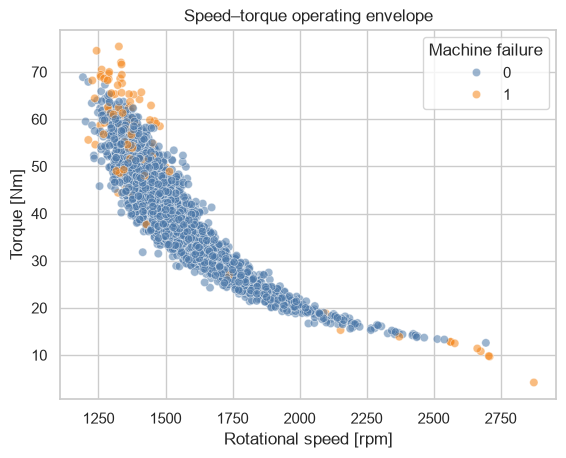

In [15]:
x=raw.sample(4000,random_state=42); sns.scatterplot(data=x,x='Rotational speed [rpm]',y='Torque [Nm]',hue=TARGET,palette={0:BLUE,1:ORANGE},alpha=.55); plt.title('Speed–torque operating envelope'); plt.show()

## 16. Tool wear interaction

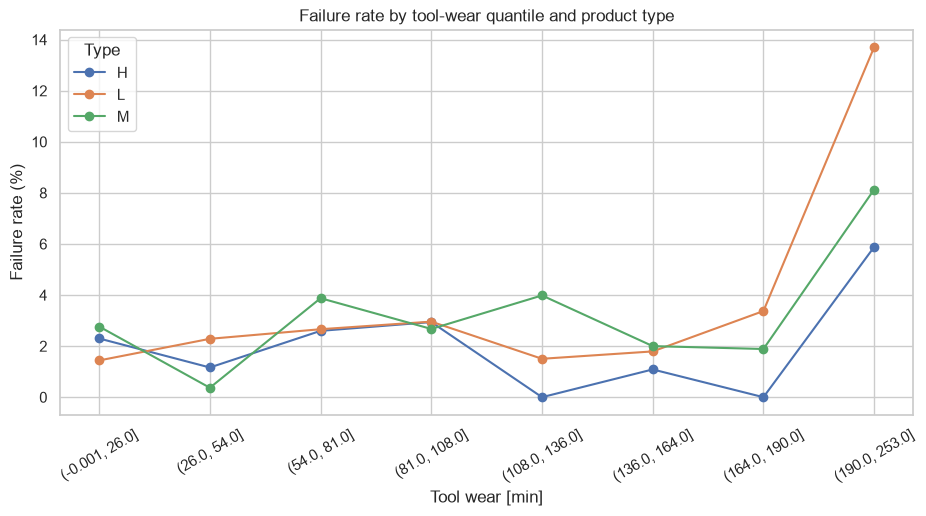

In [16]:
bins=pd.qcut(raw['Tool wear [min]'],8,duplicates='drop'); z=raw.groupby([bins,'Type'],observed=True)[TARGET].mean().unstack()*100; z.plot(marker='o',figsize=(11,5)); plt.title('Failure rate by tool-wear quantile and product type'); plt.ylabel('Failure rate (%)'); plt.xticks(rotation=30); plt.show()

## 17. Correlation matrix

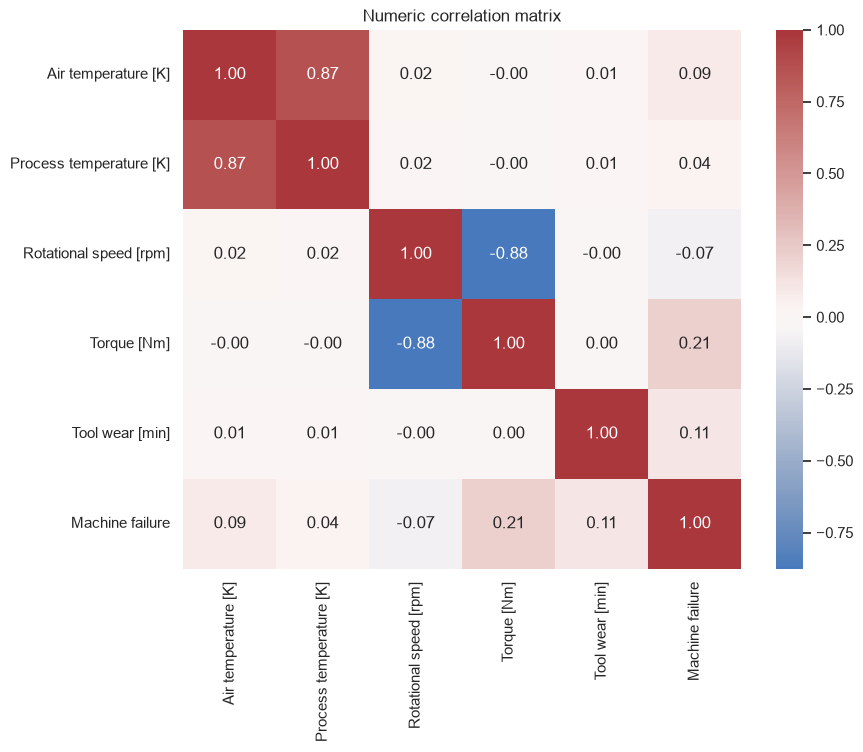

,target_correlation
Machine failure,1.0000
Torque [Nm],0.2096
Tool wear [min],0.1084
Air temperature [K],0.0869
Process temperature [K],0.0386
Rotational speed [rpm],-0.0711


In [17]:
num=BASE[1:]+[TARGET]; corr=raw[num].corr(); plt.figure(figsize=(9,7)); sns.heatmap(corr,annot=True,fmt='.2f',cmap='vlag',center=0); plt.title('Numeric correlation matrix'); plt.show(); display(corr[TARGET].sort_values(ascending=False).to_frame('target_correlation'))

## 18. Failure-mode diagnostic profile

,flagged_rows
HDF,83
OSF,74
PWF,64
TWF,32
RNF,15


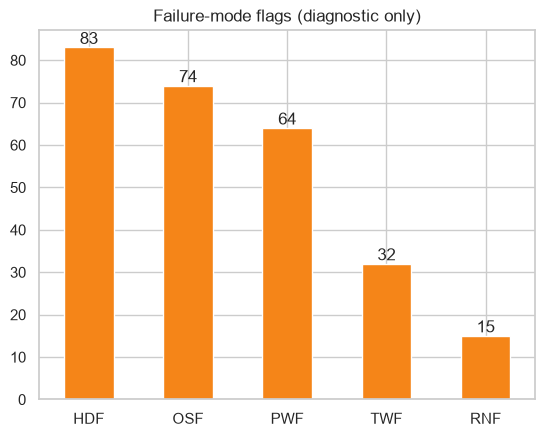

In [18]:
m=raw[LEAK].sum().sort_values(ascending=False); display(m.to_frame('flagged_rows')); ax=m.plot.bar(color=ORANGE,rot=0,title='Failure-mode flags (diagnostic only)'); ax.bar_label(ax.containers[0]); plt.show()

## 19. Aggregate target consistency

In [19]:
any_mode=raw[LEAK].max(axis=1); display(pd.crosstab(raw[TARGET],any_mode,margins=True)); print('Target/OR mismatches',raw[TARGET].ne(any_mode).sum()); print('Multiple modes',(raw[LEAK].sum(axis=1)>1).sum())

col_0,0,1,All
Machine failure,,,
0,6748,15,6763
1,6,231,237
All,6754,246,7000


Target/OR mismatches 21
Multiple modes 21


## 20. Failure-mode operating signatures

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
HDF,302.5000,310.7000,"1,346.0000",52.7000,93.0000
No mode,300.1000,310.1000,"1,506.0000",39.9000,107.0000
OSF,299.2000,309.9000,"1,362.0000",56.7000,207.0000
PWF,300.3000,310.2000,"1,399.0000",62.9000,105.0000
RNF,300.4000,310.7000,"1,505.0000",43.5000,140.0000
TWF,300.6000,310.4500,"1,501.0000",37.8500,216.0000


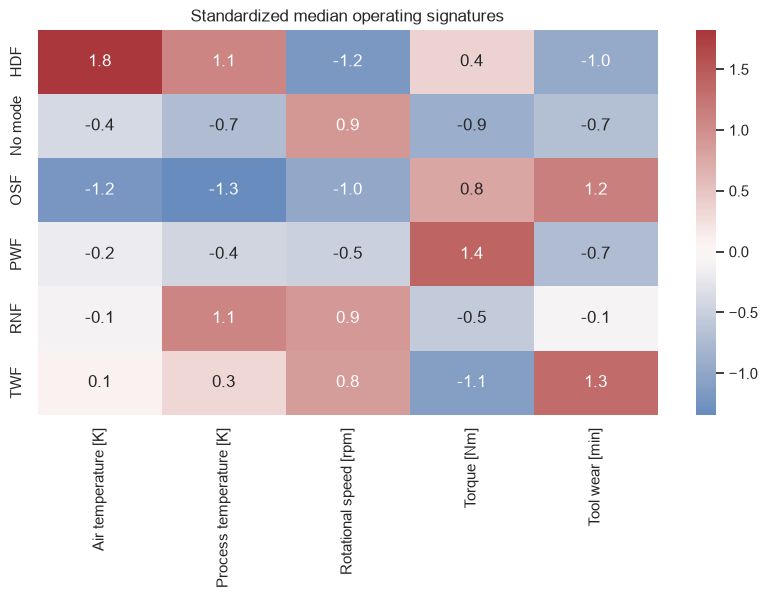

In [20]:
profile=raw.groupby(raw[LEAK].idxmax(axis=1).where(raw[LEAK].max(axis=1).eq(1),'No mode'))[BASE[1:]].median(); display(profile)
plt.figure(figsize=(10,5)); sns.heatmap(profile.apply(lambda x:(x-x.mean())/x.std()),cmap='vlag',center=0,annot=True,fmt='.1f'); plt.title('Standardized median operating signatures'); plt.show()

## 21. Identifier leakage evidence

In [21]:
print('UDI correlation with target',raw.UDI.corr(raw[TARGET])); print('Product ID uniqueness',raw['Product ID'].nunique()/len(raw)); display(raw[['UDI','Product ID',TARGET]].head())

UDI correlation with target -0.02233204995734459
Product ID uniqueness 1.0


,UDI,Product ID,Machine failure
0,932,L48111,0
1,7448,M22307,0
2,1291,L48470,0
3,1293,M16152,0
4,7044,M21903,0


## 22. EDA findings and Phase 3 recommendations

In [22]:
display(Markdown(f'''- **{raw[TARGET].sum():,} failures ({100*raw[TARGET].mean():.2f}%)** confirm severe imbalance.
- Numeric relationships are nonlinear; decile plots and the speed–torque envelope support nonlinear benchmarks.
- Tool wear, temperature delta, and mechanical power are defensible pre-outcome engineered candidates.
- Outliers are plausible operating states and should not be deleted blindly.
- Identifiers and all five failure-mode flags remain excluded from modelling.
- Phase 3 must split before fitting preprocessing or evaluating engineered features.'''))

- **237 failures (3.39%)** confirm severe imbalance.
- Numeric relationships are nonlinear; decile plots and the speed–torque envelope support nonlinear benchmarks.
- Tool wear, temperature delta, and mechanical power are defensible pre-outcome engineered candidates.
- Outliers are plausible operating states and should not be deleted blindly.
- Identifiers and all five failure-mode flags remain excluded from modelling.
- Phase 3 must split before fitting preprocessing or evaluating engineered features.